In [1]:

#  Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)


In [2]:
# data ingestion
climate_features = pd.read_csv("climate_features.csv")
test_data = pd.read_csv("Test.csv")
train_data = pd.read_csv("Train.csv")

# # data preprocessing
# # Drop rows with missing target values
# train_data = train_data.dropna(subset=[""])

# # Drop rows with missing climate features
# train_data = train_data.dropna(subset=climate_features.columns)


# Combine Train / Test with climate_features on ID
# (reloaded from the raw files because ID was dropped from train_data earlier)
climate_cols = climate_features.drop(columns=["deathdate"])  # already in Train/Test

train_merged = pd.read_csv("Train.csv").merge(climate_cols, on="ID", how="left")
test_merged = pd.read_csv("Test.csv").merge(climate_cols, on="ID", how="left")

print("train_merged:", train_merged.shape, "| missing values:", train_merged.isna().sum().sum())
print("test_merged: ", test_merged.shape, "| missing values:", test_merged.isna().sum().sum())

train_merged.head()

display(train_merged.sample(5))


train_merged: (3146, 29) | missing values: 0
test_merged:  (1030, 28) | missing values: 0


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
761,ID_DCE312D0,Rural,Female,2010-07-14,43.0,21.300468,25.599853,18.175483,0.744973,0.561774,33.535952,"Nakisenyi, Iganga, Uganda",1,1122,0,13.189013,0.69410,0.72520,8,61.325021,0.000000,406.710690,0.356825,21.422576,21.613839,21.812081,7.452876,27.130685,16.975259
2029,ID_D3B7511B,Rural,Male,2015-08-04,73.0,21.876134,26.636619,18.312935,0.575697,0.564758,33.470079,"Budhwege, Iganga, Uganda",0,1145,0,15.762794,0.64965,0.71800,11,75.843047,39.074744,407.637405,0.299996,21.680798,21.335543,21.704414,8.331731,27.511819,15.912683
2344,ID_2F206D6A,Peri_urban,Male,2017-04-28,31.0,22.385040,26.896979,18.805994,0.958627,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1,1110,0,23.569546,0.73120,0.62715,18,198.994416,71.793488,479.265711,0.196194,23.224073,22.616899,23.533727,8.039598,29.551080,18.782312
519,ID_1C9747C1,Peri_urban,Male,2009-11-17,35.0,20.469793,25.218042,17.635576,2.892800,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,20.638350,0.59400,0.60280,14,125.596560,16.957952,342.112244,0.166667,21.988324,21.670363,22.012613,7.083748,28.144586,17.995813
1318,ID_07B4F38C,Peri_urban,Male,2012-06-15,1.0,21.245486,24.526690,18.484211,2.833942,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,19.092361,0.59495,0.56115,11,121.969264,14.417118,493.233250,0.166667,21.477283,21.925433,21.999240,7.269978,27.402307,17.272134


In [3]:
train_merged.info()
train_merged.describe()
# EDA

# drop id (test_merged keeps its ID for the submission file)
train_merged = train_merged.drop(columns=["ID"])

# drop duplicates
train_merged = train_merged.drop_duplicates()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
 13  elevation             3146 non-null   int64  
 14  hot_days_30d          3146 non-null   int64  
 15  max_daily_rain_30d   

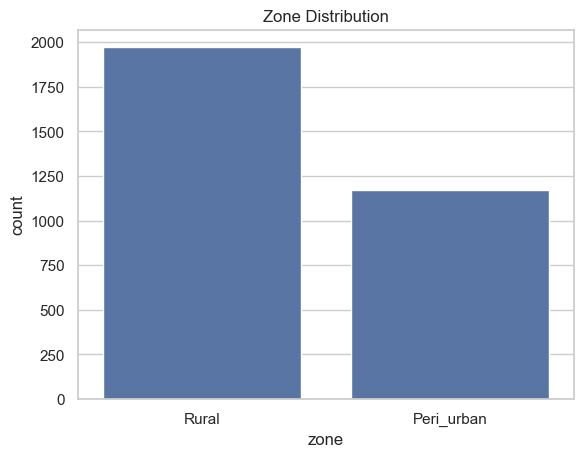

In [4]:
# EDA
# train_data Analysis -- CATEGORICAL DATA
train_merged['zone'].value_counts()
sns.countplot(x='zone', data=train_merged)
plt.title('Zone Distribution')
plt.show()

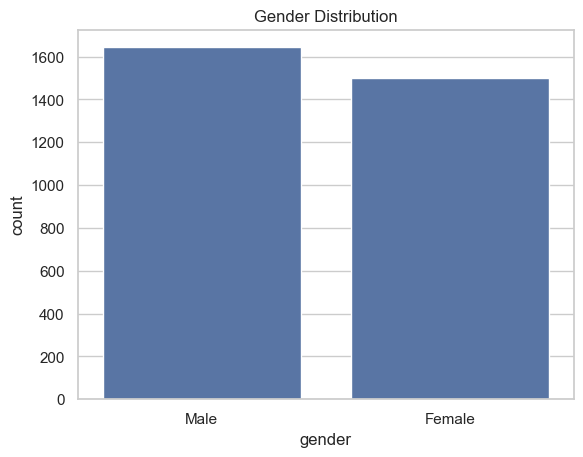

In [5]:
train_merged['gender'].value_counts()
sns.countplot(x='gender', data=train_merged)
plt.title('Gender Distribution')
plt.show()

In [6]:
# Normalize the location text so the variants merge into one consistent value
# (fix the "Propeer"/"Buwoya" typos, drop the stray ", Eastern Region" segment,
# collapse leftover double commas/spaces, and use consistent casing)
train_merged['location'] = (
    train_merged['location']
    .str.replace('Propeer', 'Proper', regex=False)
    .str.replace('Buwoya', 'Buwaya', regex=False)
    .str.replace(', Eastern Region', '', regex=False)
    .str.replace(r',\s*,', ',', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.replace(r'\s*,\s*', ', ', regex=True)
    .str.title()
)

# Locations that still appear more than once after cleaning
duplicate_locations = train_merged[train_merged.duplicated(subset=['location'], keep=False)]

location_counts = train_merged['location'].value_counts()
duplicated_location_counts = location_counts[location_counts > 1].sort_index()

duplicated_location_counts

location
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Proper, Kasokoso North, Iganga, Uganda        417
Budhwege, Iganga, Uganda                                                                                80
Bukoyo, Iganga, Uganda                                                                                  31
Bukwaya, Iganga, Uganda                                                                                 79
Buligo North, Iganga, Uganda                                                                            81
Buligo South, Iganga, Uganda                                                                            97
Bulubandi Central B, Iganga, Uganda                                                                      9
Bulumwaki Church Of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Uganda    155
Buluza, Iganga, Uganda                                                                                  96
Bulyampindi Nursery School, 

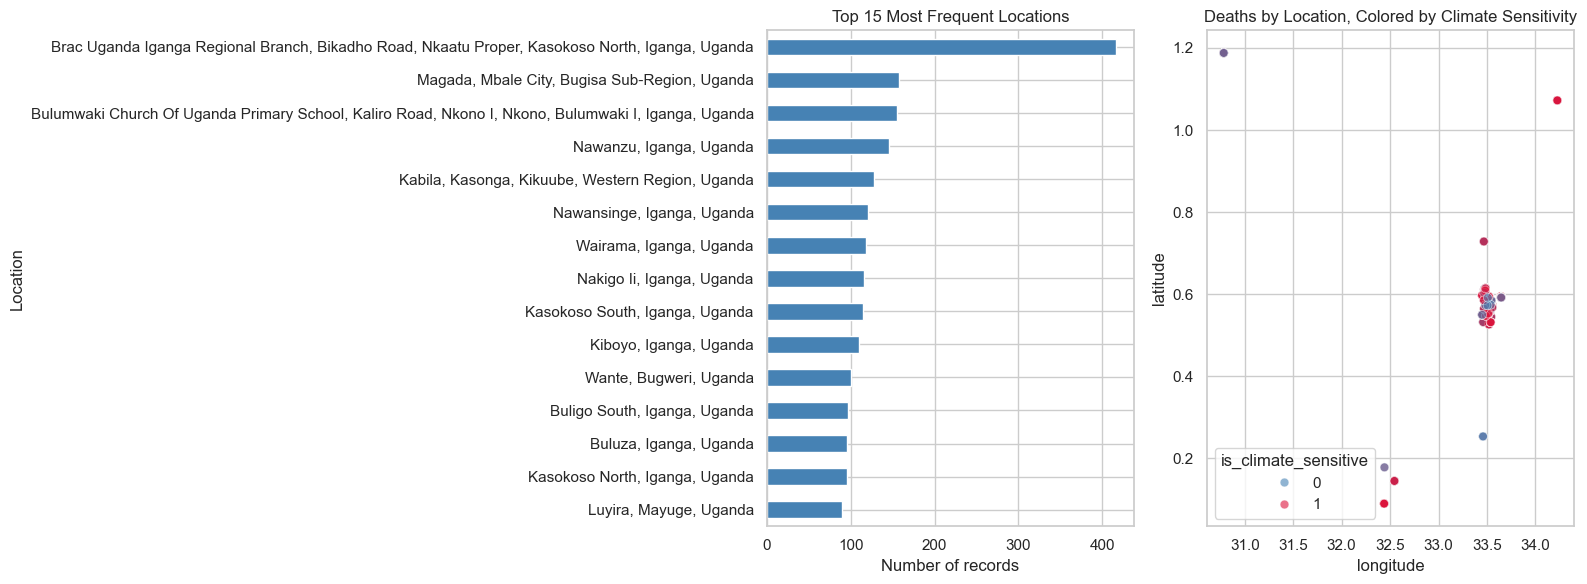

In [7]:
# location is high-cardinality free text (near-unique addresses), so a full
# categorical bar plot isn't readable. Instead: top-N most frequent locations,
# and a geospatial scatter (lat/long) colored by target, which is far more
# informative for a location field than plotting raw address strings.
top_locations = train_merged['location'].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_locations.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 15 Most Frequent Locations')
axes[0].set_xlabel('Number of records')
axes[0].set_ylabel('Location')

sns.scatterplot(
    data=train_merged,
    x='longitude',
    y='latitude',
    hue='is_climate_sensitive',
    palette={0: 'steelblue', 1: 'crimson'},
    alpha=0.6,
    s=40,
    ax=axes[1],
)
axes[1].set_title('Deaths by Location, Colored by Climate Sensitivity')

plt.tight_layout()
plt.show()

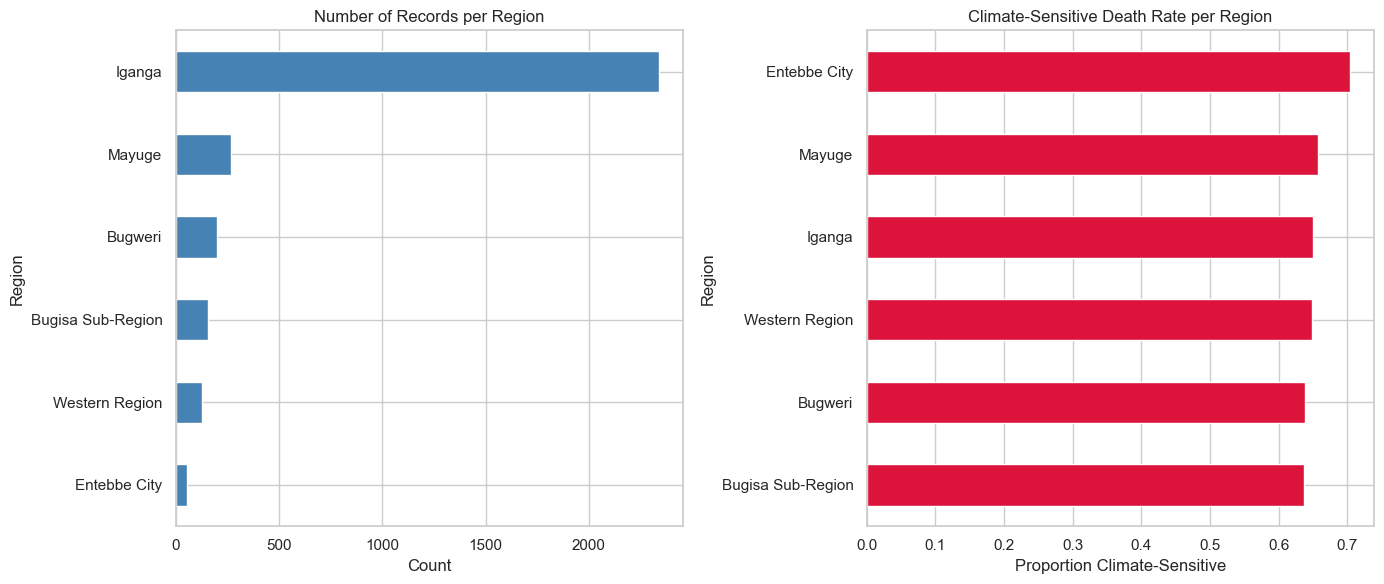

In [8]:
# Extract region: the segment right before ", Uganda" in the location string
train_merged['region'] =  train_merged['location'].str.split(',').str[-2].str.strip()

train_merged['region'].value_counts()

# region is proper low-cardinality categorical now, so a count + target-rate
# bar chart works well (unlike raw location)
region_counts = train_merged['region'].value_counts().sort_values()
region_rate = train_merged.groupby('region')['is_climate_sensitive'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

region_counts.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Number of Records per Region')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Region')

region_rate.plot(kind='barh', ax=axes[1], color='crimson')
axes[1].set_title('Climate-Sensitive Death Rate per Region')
axes[1].set_xlabel('Proportion Climate-Sensitive')
axes[1].set_ylabel('Region')

plt.tight_layout()
plt.show()

In [9]:
# Death Date

# Group region, death_date, and is_climate_sensitive to get counts of
# climate-sensitive deaths per region per year
train_merged['deathdate'] = pd.to_datetime(train_merged['deathdate'])
train_merged['death_year'] = train_merged['deathdate'].dt.year

region_year_counts = (
    train_merged
    .groupby(['region', 'death_year', 'is_climate_sensitive'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

region_year_counts

,region,death_year,is_climate_sensitive,count
85,Iganga,2009,1,257
87,Iganga,2010,1,194
89,Iganga,2011,1,146
91,Iganga,2012,1,122
93,Iganga,2013,1,120
...,...,...,...,...
80,Entebbe City,2021,1,1
81,Iganga,2007,1,1
141,Western Region,2008,0,1
130,Mayuge,2017,0,1


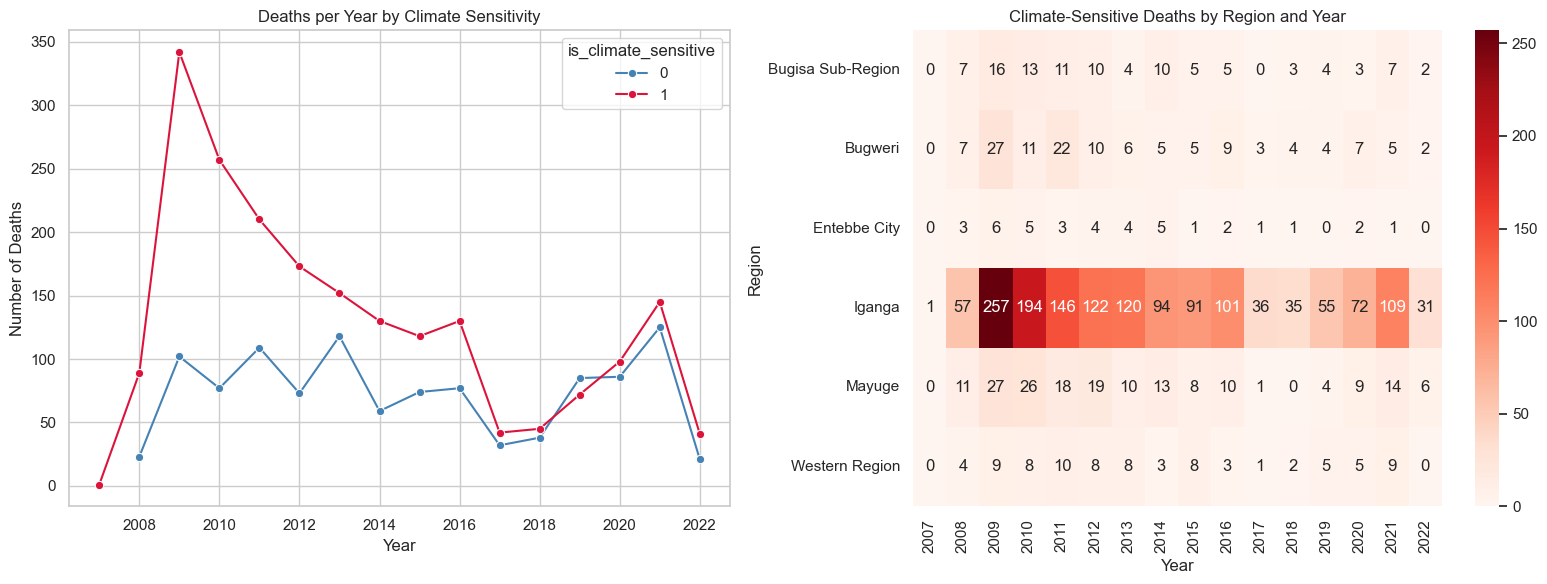

In [10]:
# Visualize: overall yearly trend of climate-sensitive vs other deaths, and
# a region x year heatmap of climate-sensitive death counts
yearly_counts = (
    train_merged
    .groupby(['death_year', 'is_climate_sensitive'])
    .size()
    .reset_index(name='count')
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=yearly_counts,
    x='death_year',
    y='count',
    hue='is_climate_sensitive',
    marker='o',
    palette={0: 'steelblue', 1: 'crimson'},
    ax=axes[0],
)
axes[0].set_title('Deaths per Year by Climate Sensitivity')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Deaths')

climate_sensitive_pivot = (
    region_year_counts[region_year_counts['is_climate_sensitive'] == 1]
    .pivot(index='region', columns='death_year', values='count')
    .fillna(0)
)

sns.heatmap(climate_sensitive_pivot, cmap='Reds', annot=True, fmt='.0f', ax=axes[1])
axes[1].set_title('Climate-Sensitive Deaths by Region and Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Region')

plt.tight_layout()
plt.show()

,climate_sensitive_deaths,total_deaths,climate_sensitive_rate
age_group,,,
0-4,1447,1731,0.835933
5-17,87,139,0.625899
18-39,177,339,0.522124
40-59,140,289,0.484429
60+,194,646,0.300310


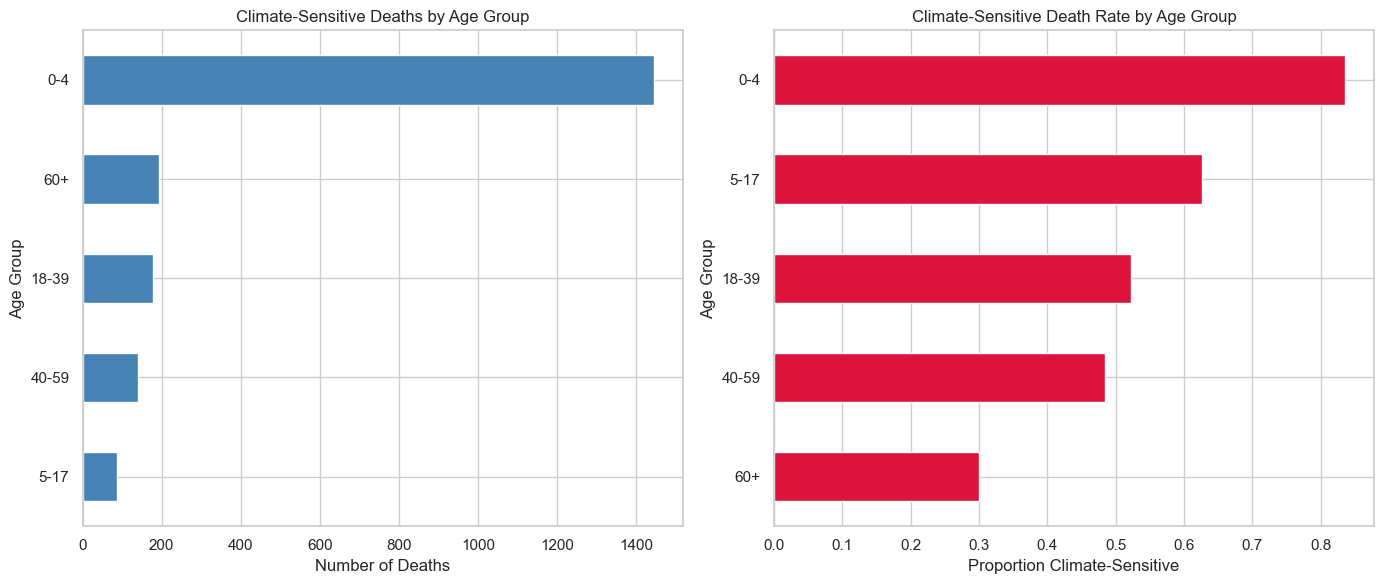

In [11]:
# Age groups most affected by climate-sensitive deaths
age_bins = [-1, 4, 17, 39, 59, np.inf]
age_labels = ["0-4", "5-17", "18-39", "40-59", "60+"]
age_group_for_analysis = pd.cut(train_merged['age'], bins=age_bins, labels=age_labels)

age_group_stats = (
    train_merged
    .assign(age_group=age_group_for_analysis)
    .groupby('age_group', observed=True)['is_climate_sensitive']
    .agg(climate_sensitive_deaths='sum', total_deaths='count', climate_sensitive_rate='mean')
    .sort_values('climate_sensitive_rate', ascending=False)
)

display(age_group_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

age_group_stats['climate_sensitive_deaths'].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue'
)
axes[0].set_title('Climate-Sensitive Deaths by Age Group')
axes[0].set_xlabel('Number of Deaths')
axes[0].set_ylabel('Age Group')

age_group_stats['climate_sensitive_rate'].sort_values().plot(
    kind='barh', ax=axes[1], color='crimson'
)
axes[1].set_title('Climate-Sensitive Death Rate by Age Group')
axes[1].set_xlabel('Proportion Climate-Sensitive')
axes[1].set_ylabel('Age Group')

plt.tight_layout()
plt.show()

In [12]:
# Feature engineering 

#  Time: month and Uganda's rainy seasons (Mar-May, Sep-Nov)
train_merged['death_month'] = train_merged['deathdate'].dt.month
train_merged['is_rainy_season'] = train_merged['death_month'].isin([3, 4, 5, 9, 10, 11]).astype(int)

#  Rainfall: how wet the recent past was, and how sudden / intense it was
train_merged['log_precipitation'] = np.log1p(train_merged['precipitation'])
train_merged['rain_intensity_30d'] = train_merged['rain_sum_30d'] / (train_merged['rain_days_30d'] + 1)
train_merged['rain_recent_ratio'] = train_merged['rain_sum_7d'] / (train_merged['rain_sum_30d'] + 1)
train_merged['rain_30d_vs_90d'] = train_merged['rain_sum_30d'] / (train_merged['rain_sum_90d'] + 1)

#  Temperature: daily swing and short-term anomalies vs the longer baseline
train_merged['temp_range'] = train_merged['max_temperature'] - train_merged['min_temperature']
train_merged['temp_anomaly_7d'] = train_merged['tavg_7d'] - train_merged['tavg_90d']
train_merged['heat_stress_30d'] = train_merged['tmax_30d'] - train_merged['tavg_90d']

#  Vegetation: is greenness rising or falling (drought / crop stress signal)
train_merged['ndvi_change'] = train_merged['ndvi_30d'] - train_merged['ndvi_90d']

#  Age vulnerability flags and an interaction with recent rainfall
train_merged['is_infant'] = (train_merged['age'] == 0).astype(int)
train_merged['is_under5'] = (train_merged['age'] < 5).astype(int)
train_merged['is_elderly'] = (train_merged['age'] >= 60).astype(int)
train_merged['under5_x_rain30'] = train_merged['is_under5'] * train_merged['rain_sum_30d']

new_features = [
    'death_month', 'is_rainy_season', 'log_precipitation', 'rain_intensity_30d',
    'rain_recent_ratio', 'rain_30d_vs_90d', 'temp_range', 'temp_anomaly_7d',
    'heat_stress_30d', 'ndvi_change', 'is_infant', 'is_under5', 'is_elderly',
    'under5_x_rain30',
]
train_merged[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
death_month,3144.0,6.503817,3.427257,1.000000,4.000000,6.000000,9.000000,12.000000
is_rainy_season,3144.0,0.477417,0.499569,0.000000,0.000000,0.000000,1.000000,1.000000
log_precipitation,3144.0,0.757390,0.560546,0.000000,0.251794,0.710174,1.170165,2.868269
rain_intensity_30d,3144.0,8.247260,2.958701,0.000000,6.323435,8.036923,9.752334,28.865039
rain_recent_ratio,3144.0,0.232591,0.167372,0.000000,0.113767,0.216202,0.325071,0.983198
rain_30d_vs_90d,3144.0,0.334465,0.157834,0.000000,0.208384,0.328532,0.445075,0.851607
temp_range,3144.0,7.692788,1.681969,2.434404,6.726671,7.641007,8.643520,15.734164
temp_anomaly_7d,3144.0,-0.024700,0.785302,-2.675991,-0.552272,-0.061527,0.465727,2.516055
heat_stress_30d,3144.0,6.229534,1.232405,2.017064,5.413655,6.123975,6.890016,10.787786
ndvi_change,3144.0,-0.002349,0.050342,-0.420400,-0.025850,0.000000,0.023475,0.278850


In [13]:
# perform encoding on the categorical variables
# One-hot encode gender, zone, and region using sklearn's OneHotEncoder.
# location is excluded (too high-cardinality/free-text for one-hot), and
# deathdate is dropped since death_year already captures its year signal
categorical_cols = ['gender', 'zone', 'region']

encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
encoded_array = encoder.fit_transform(train_merged[categorical_cols])
encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=train_merged.index,
)

train_merged = pd.concat([train_merged.drop(columns=categorical_cols), encoded_df], axis=1)
train_merged = train_merged.drop(columns=['location', 'deathdate'])

train_merged.sample(5)

,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,death_year,death_month,is_rainy_season,log_precipitation,rain_intensity_30d,rain_recent_ratio,rain_30d_vs_90d,temp_range,temp_anomaly_7d,heat_stress_30d,ndvi_change,is_infant,is_under5,is_elderly,under5_x_rain30,gender_Male,zone_Rural,region_Bugweri,region_Entebbe City,region_Iganga,region_Mayuge,region_Western Region
179,1.0,23.694896,28.975261,18.632220,0.027047,0.561774,33.535952,0,1122,0,22.355431,0.63690,0.5739,15,89.886472,0.000000,116.296554,0.356825,22.440147,23.164419,22.552892,8.256871,30.224039,17.101907,2009,2,0,0.026687,5.617905,0.000000,0.766318,10.343041,0.611526,7.671146,0.06300,0,1,0,89.886472,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2659,0.0,23.548687,27.268316,20.431452,1.263279,0.605119,33.475691,0,1132,0,28.159615,0.51925,0.5368,11,110.274777,7.408512,498.719656,0.166667,22.609370,23.629711,22.223638,7.811603,29.614267,16.820566,2020,2,0,0.816815,9.189565,0.066579,0.220673,6.836864,1.406073,7.390629,-0.01755,1,1,0,110.274777,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1689,55.0,20.750072,24.054725,18.227810,3.134704,0.550000,33.450000,0,1130,0,13.063687,0.67885,0.6554,12,80.780558,26.127375,375.330819,0.195107,21.775031,21.248960,21.582705,7.739407,27.595758,17.222955,2013,11,1,1.419416,6.213889,0.319481,0.214653,5.826915,-0.333745,6.013053,0.02345,0,0,0,0.000000,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1448,0.0,21.867667,25.520474,17.997302,1.297367,0.531798,33.538415,1,1157,0,23.091761,0.73130,0.7313,13,121.164048,24.182604,465.039043,0.324049,21.920613,21.931295,21.775389,6.563433,26.628320,18.048212,2012,12,0,0.831764,8.654575,0.197952,0.259987,7.523172,0.155906,4.852931,0.00000,1,1,0,121.164048,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2491,0.0,24.944424,30.613512,20.253434,0.137032,0.615049,33.485670,0,1132,0,8.726753,0.43545,0.4931,6,28.526146,4.519177,201.615167,0.166667,23.792696,25.150620,22.970466,9.100290,31.466425,18.271814,2019,2,0,0.128421,4.075164,0.153057,0.140790,10.360077,2.180154,8.495958,-0.05765,1,1,0,28.526146,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [14]:
train_merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3144 entries, 0 to 3145
Data columns (total 46 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3144 non-null   float64
 1   avg_temperature        3144 non-null   float64
 2   max_temperature        3144 non-null   float64
 3   min_temperature        3144 non-null   float64
 4   precipitation          3144 non-null   float64
 5   latitude               3144 non-null   float64
 6   longitude              3144 non-null   float64
 7   is_climate_sensitive   3144 non-null   int64  
 8   elevation              3144 non-null   int64  
 9   hot_days_30d           3144 non-null   int64  
 10  max_daily_rain_30d     3144 non-null   float64
 11  ndvi_30d               3144 non-null   float64
 12  ndvi_90d               3144 non-null   float64
 13  rain_days_30d          3144 non-null   int64  
 14  rain_sum_30d           3144 non-null   float64
 15  rain_sum_

In [15]:

# Split the data into features and target variable
X = train_merged.drop(columns=["is_climate_sensitive"]) 
y = train_merged["is_climate_sensitive"] 


print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (3144, 45)
Target shape: (3144,)


In [16]:
# Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train.shape, X_val.shape, y_train.shape, y_val.shape

((2515, 45), (629, 45), (2515,), (629,))

F1-score:        0.7617
ROC-AUC:          0.8104
Combined (60/40): 0.7812

              precision    recall  f1-score   support

           0       0.57      0.75      0.65       220
           1       0.84      0.70      0.76       409

    accuracy                           0.72       629
   macro avg       0.70      0.72      0.70       629
weighted avg       0.74      0.72      0.72       629



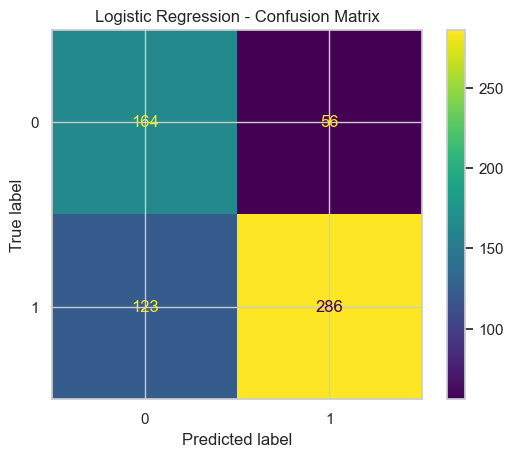

In [17]:
# Logistic Regression baseline 
# Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Scale the numeric/continuous features (LR is scale-sensitive); the
# one-hot dummy columns and 0/1 flags are left as-is
numeric_features = [
    'age', 'avg_temperature', 'max_temperature', 'min_temperature',
    'precipitation', 'latitude', 'longitude', 'death_year',
    # merged climate_features columns
    'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d',
    'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope',
    'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d',
    # engineered continuous features
    'death_month', 'log_precipitation', 'rain_intensity_30d', 'rain_recent_ratio',
    'rain_30d_vs_90d', 'temp_range', 'temp_anomaly_7d', 'heat_stress_30d',
    'ndvi_change', 'under5_x_rain30',
]
numeric_features = [c for c in numeric_features if c in X_train.columns]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_val_scaled[numeric_features] = scaler.transform(X_val[numeric_features])

model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred = model.predict(X_val_scaled)
y_val_proba = model.predict_proba(X_val_scaled)[:, 1]

f1 = f1_score(y_val, y_val_pred)
auc = roc_auc_score(y_val, y_val_proba)
combined_score = 0.6 * f1 + 0.4 * auc

print(f"F1-score:        {f1:.4f}")
print(f"ROC-AUC:          {auc:.4f}")
print(f"Combined (60/40): {combined_score:.4f}")
print()
print(classification_report(y_val, y_val_pred))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

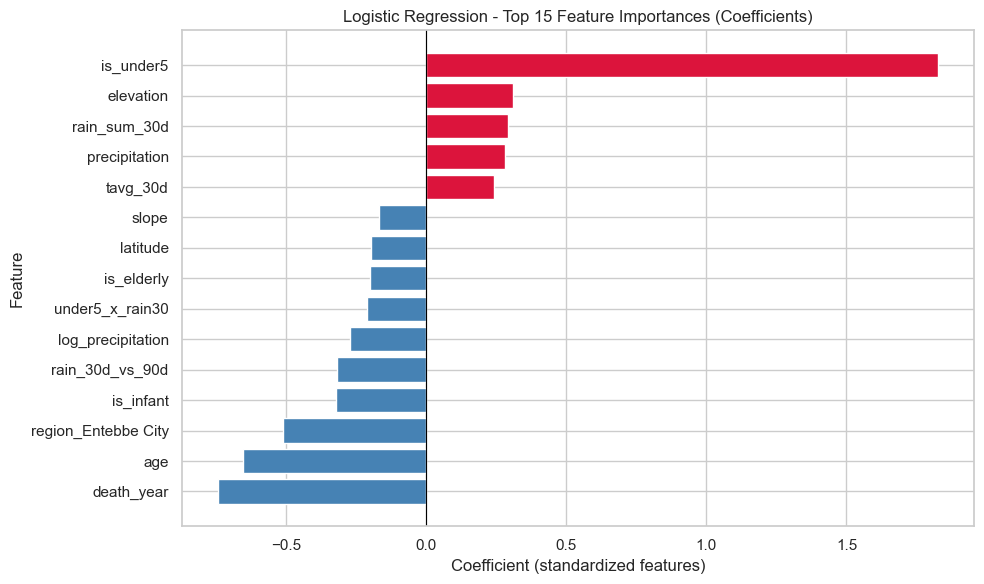

,feature,coefficient,abs_coefficient
35,is_under5,1.826448,1.826448
23,death_year,-0.742031,0.742031
0,age,-0.651365,0.651365
41,region_Entebbe City,-0.508254,0.508254
34,is_infant,-0.320866,0.320866
29,rain_30d_vs_90d,-0.317945,0.317945
7,elevation,0.310699,0.310699
13,rain_sum_30d,0.291805,0.291805
4,precipitation,0.283693,0.283693
26,log_precipitation,-0.269875,0.269875


In [18]:
# Logistic Regression - Feature Importance
# Coefficients are comparable because features were standardized before
# fitting; sign shows direction (positive -> pushes toward climate-sensitive)
lr_importance = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'coefficient': model.coef_[0],
})
lr_importance['abs_coefficient'] = lr_importance['coefficient'].abs()
lr_importance = lr_importance.sort_values('abs_coefficient', ascending=False)

top_n = 15
top_lr_importance = lr_importance.head(top_n).sort_values('coefficient')

plt.figure(figsize=(10, 6))
colors = top_lr_importance['coefficient'].apply(lambda c: 'crimson' if c > 0 else 'steelblue')
plt.barh(top_lr_importance['feature'], top_lr_importance['coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f'Logistic Regression - Top {top_n} Feature Importances (Coefficients)')
plt.xlabel('Coefficient (standardized features)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

lr_importance.head(top_n)

F1-score:        0.7991
ROC-AUC:          0.8070
Combined (60/40): 0.8022

              precision    recall  f1-score   support

           0       0.63      0.54      0.58       220
           1       0.77      0.83      0.80       409

    accuracy                           0.73       629
   macro avg       0.70      0.68      0.69       629
weighted avg       0.72      0.73      0.72       629



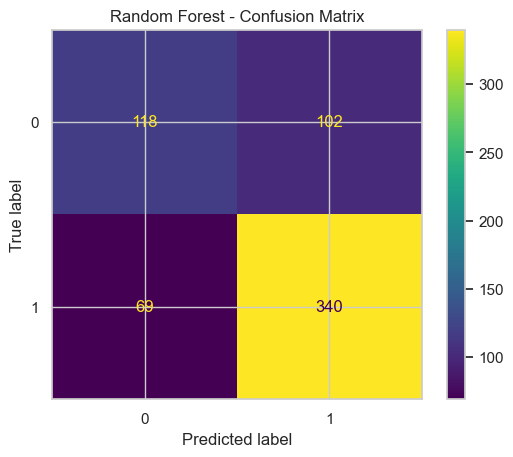

In [19]:
# Random Forest (no scaling needed - trees are scale-invariant)
rf_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42
)
rf_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_rf = rf_model.predict(X_val)
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]

f1_rf = f1_score(y_val, y_val_pred_rf)
auc_rf = roc_auc_score(y_val, y_val_proba_rf)
combined_score_rf = 0.6 * f1_rf + 0.4 * auc_rf

print(f"F1-score:        {f1_rf:.4f}")
print(f"ROC-AUC:          {auc_rf:.4f}")
print(f"Combined (60/40): {combined_score_rf:.4f}")
print()
print(classification_report(y_val, y_val_pred_rf))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_rf)
plt.title('Random Forest - Confusion Matrix')
plt.show()

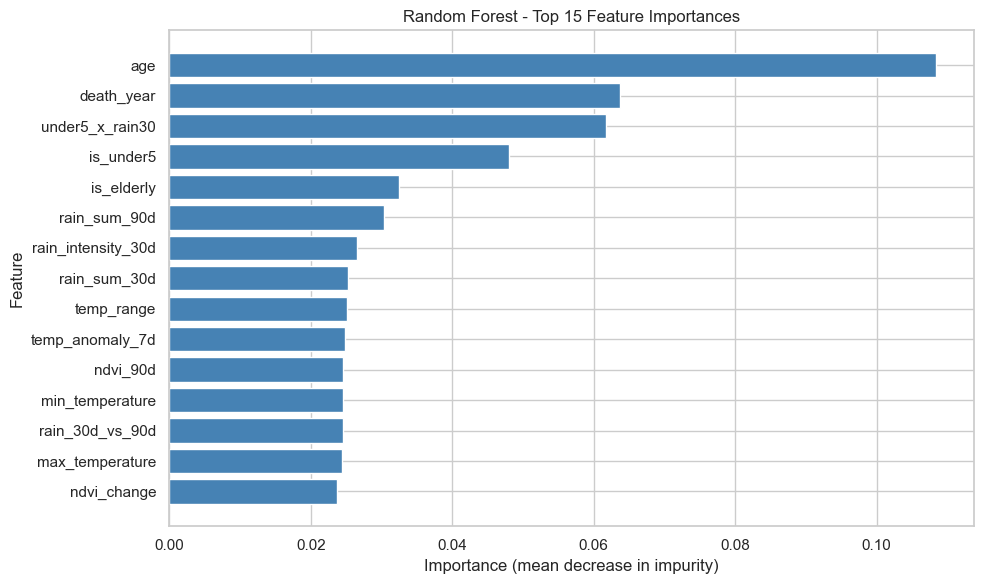

,feature,importance
0,age,0.108362
23,death_year,0.063686
37,under5_x_rain30,0.061674
35,is_under5,0.048077
36,is_elderly,0.032467
15,rain_sum_90d,0.030416
27,rain_intensity_30d,0.026482
13,rain_sum_30d,0.025261
30,temp_range,0.025132
31,temp_anomaly_7d,0.024781


In [20]:
# Random Forest - Feature Importance
# Mean decrease in impurity (Gini importance) - unsigned, unlike LR coefficients
rf_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf_model.feature_importances_,
}).sort_values('importance', ascending=False)

top_n = 15
top_rf_importance = rf_importance.head(top_n).sort_values('importance')

plt.figure(figsize=(10, 6))
plt.barh(top_rf_importance['feature'], top_rf_importance['importance'], color='steelblue')
plt.title(f'Random Forest - Top {top_n} Feature Importances')
plt.xlabel('Importance (mean decrease in impurity)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

rf_importance.head(top_n)

Dropping 8 low-importance (noise) features:
['zone_Rural', 'region_Iganga', 'is_rainy_season', 'region_Mayuge', 'region_Bugweri', 'region_Entebbe City', 'region_Western Region', 'hot_days_30d']

F1-score:        0.8047  (vs 0.7991 with all features)
ROC-AUC:          0.8066  (vs 0.8070 with all features)
Combined (60/40): 0.8055  (vs 0.8022 with all features)

              precision    recall  f1-score   support

           0       0.64      0.55      0.59       220
           1       0.78      0.84      0.80       409

    accuracy                           0.74       629
   macro avg       0.71      0.69      0.70       629
weighted avg       0.73      0.74      0.73       629



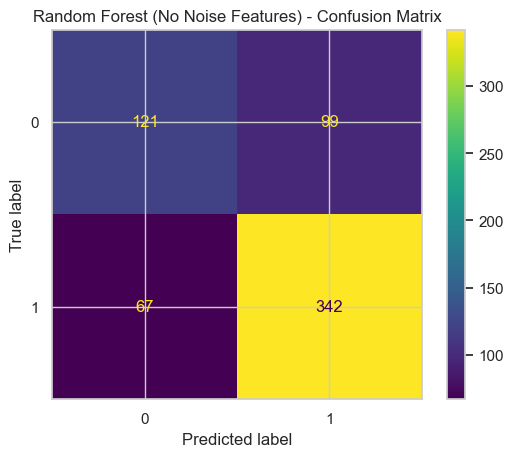

In [21]:
# Random Forest without noise features
# Drop features whose importance is below a small threshold - mostly the
# one-hot region/zone dummies and hot_days_30d (which is constant / all
# zeros in this data, so it can carry no signal at all)
noise_threshold = 0.005
noise_features = rf_importance.loc[rf_importance['importance'] < noise_threshold, 'feature'].tolist()

print(f"Dropping {len(noise_features)} low-importance (noise) features:")
print(noise_features)

X_train_denoised = X_train.drop(columns=noise_features)
X_val_denoised = X_val.drop(columns=noise_features)

rf_denoised_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42
)
rf_denoised_model.fit(X_train_denoised, y_train)

y_val_pred_rf_denoised = rf_denoised_model.predict(X_val_denoised)
y_val_proba_rf_denoised = rf_denoised_model.predict_proba(X_val_denoised)[:, 1]

f1_rf_denoised = f1_score(y_val, y_val_pred_rf_denoised)
auc_rf_denoised = roc_auc_score(y_val, y_val_proba_rf_denoised)
combined_score_rf_denoised = 0.6 * f1_rf_denoised + 0.4 * auc_rf_denoised

print()
print(f"F1-score:        {f1_rf_denoised:.4f}  (vs {f1_rf:.4f} with all features)")
print(f"ROC-AUC:          {auc_rf_denoised:.4f}  (vs {auc_rf:.4f} with all features)")
print(f"Combined (60/40): {combined_score_rf_denoised:.4f}  (vs {combined_score_rf:.4f} with all features)")
print()
print(classification_report(y_val, y_val_pred_rf_denoised))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_rf_denoised)
plt.title('Random Forest (No Noise Features) - Confusion Matrix')
plt.show()

F1-score:        0.7700
ROC-AUC:          0.7862
Combined (60/40): 0.7765

              precision    recall  f1-score   support

           0       0.57      0.55      0.56       220
           1       0.76      0.78      0.77       409

    accuracy                           0.70       629
   macro avg       0.67      0.66      0.67       629
weighted avg       0.70      0.70      0.70       629



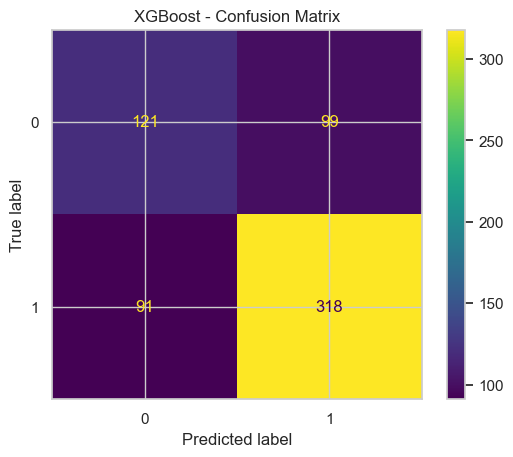

In [22]:

# XGBoost (no scaling needed - trees are scale-invariant)
# XGBoost has no class_weight param, so imbalance is handled via
# scale_pos_weight = negative_count / positive_count
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
)
xgb_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

f1_xgb = f1_score(y_val, y_val_pred_xgb)
auc_xgb = roc_auc_score(y_val, y_val_proba_xgb)
combined_score_xgb = 0.6 * f1_xgb + 0.4 * auc_xgb

print(f"F1-score:        {f1_xgb:.4f}")
print(f"ROC-AUC:          {auc_xgb:.4f}")
print(f"Combined (60/40): {combined_score_xgb:.4f}")
print()
print(classification_report(y_val, y_val_pred_xgb))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_xgb)
plt.title('XGBoost - Confusion Matrix')
plt.show()

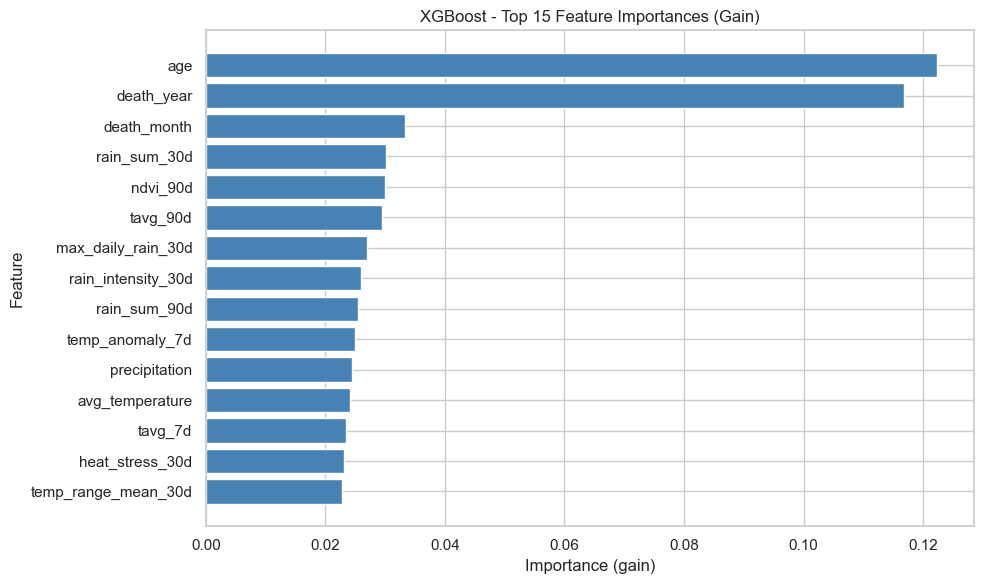

,feature,importance
0,age,0.122400
23,death_year,0.116814
24,death_month,0.033336
13,rain_sum_30d,0.030170
11,ndvi_90d,0.029907
19,tavg_90d,0.029529
9,max_daily_rain_30d,0.027003
27,rain_intensity_30d,0.025945
15,rain_sum_90d,0.025552
31,temp_anomaly_7d,0.025028


In [23]:
# XGBoost - Feature Importance
# Default XGBClassifier importance_type is 'gain' - average improvement in
# the loss function brought by a feature when it is used in a split
xgb_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_model.feature_importances_,
}).sort_values('importance', ascending=False)

top_n = 15
top_xgb_importance = xgb_importance.head(top_n).sort_values('importance')

plt.figure(figsize=(10, 6))
plt.barh(top_xgb_importance['feature'], top_xgb_importance['importance'], color='steelblue')
plt.title(f'XGBoost - Top {top_n} Feature Importances (Gain)')
plt.xlabel('Importance (gain)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

xgb_importance.head(top_n)

Dropping 10 low-importance (noise) features:
['zone_Rural', 'region_Mayuge', 'region_Entebbe City', 'region_Bugweri', 'is_infant', 'is_elderly', 'is_under5', 'hot_days_30d', 'log_precipitation', 'region_Western Region']

F1-score:        0.7737  (vs 0.7700 with all features)
ROC-AUC:          0.7871  (vs 0.7862 with all features)
Combined (60/40): 0.7791  (vs 0.7765 with all features)

              precision    recall  f1-score   support

           0       0.58      0.57      0.57       220
           1       0.77      0.78      0.77       409

    accuracy                           0.70       629
   macro avg       0.67      0.67      0.67       629
weighted avg       0.70      0.70      0.70       629



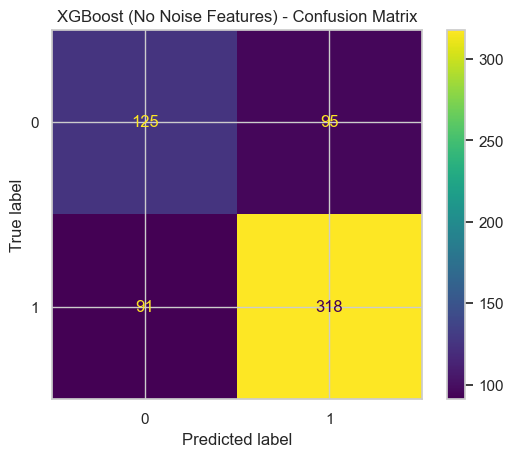

In [24]:
# XGBoost without noise features
# Same threshold as the Random Forest denoising step - drop features whose
# gain is below a small cutoff
noise_threshold = 0.005
xgb_noise_features = xgb_importance.loc[xgb_importance['importance'] < noise_threshold, 'feature'].tolist()

print(f"Dropping {len(xgb_noise_features)} low-importance (noise) features:")
print(xgb_noise_features)

X_train_denoised_xgb = X_train.drop(columns=xgb_noise_features)
X_val_denoised_xgb = X_val.drop(columns=xgb_noise_features)

xgb_denoised_model = XGBClassifier(
    n_estimators=300,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
)
xgb_denoised_model.fit(X_train_denoised_xgb, y_train)

y_val_pred_xgb_denoised = xgb_denoised_model.predict(X_val_denoised_xgb)
y_val_proba_xgb_denoised = xgb_denoised_model.predict_proba(X_val_denoised_xgb)[:, 1]

f1_xgb_denoised = f1_score(y_val, y_val_pred_xgb_denoised)
auc_xgb_denoised = roc_auc_score(y_val, y_val_proba_xgb_denoised)
combined_score_xgb_denoised = 0.6 * f1_xgb_denoised + 0.4 * auc_xgb_denoised

print()
print(f"F1-score:        {f1_xgb_denoised:.4f}  (vs {f1_xgb:.4f} with all features)")
print(f"ROC-AUC:          {auc_xgb_denoised:.4f}  (vs {auc_xgb:.4f} with all features)")
print(f"Combined (60/40): {combined_score_xgb_denoised:.4f}  (vs {combined_score_xgb:.4f} with all features)")
print()
print(classification_report(y_val, y_val_pred_xgb_denoised))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_xgb_denoised)
plt.title('XGBoost (No Noise Features) - Confusion Matrix')
plt.show()

F1-score:        0.7638
ROC-AUC:          0.8117
Combined (60/40): 0.7829

              precision    recall  f1-score   support

           0       0.57      0.72      0.64       220
           1       0.82      0.71      0.76       409

    accuracy                           0.71       629
   macro avg       0.70      0.71      0.70       629
weighted avg       0.74      0.71      0.72       629



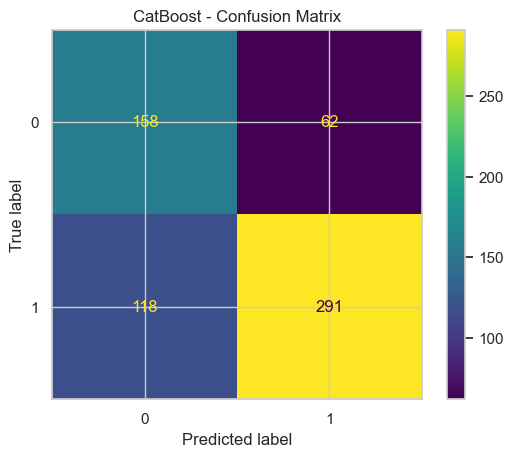

In [25]:
# CatBoost (no scaling needed - trees are scale-invariant)
# Class imbalance is handled via auto_class_weights (CatBoost's equivalent
# of sklearn's class_weight='balanced')
catboost_model = CatBoostClassifier(
    n_estimators=300,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0,
)
catboost_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_catboost = catboost_model.predict(X_val)
y_val_proba_catboost = catboost_model.predict_proba(X_val)[:, 1]

f1_catboost = f1_score(y_val, y_val_pred_catboost)
auc_catboost = roc_auc_score(y_val, y_val_proba_catboost)
combined_score_catboost = 0.6 * f1_catboost + 0.4 * auc_catboost

print(f"F1-score:        {f1_catboost:.4f}")
print(f"ROC-AUC:          {auc_catboost:.4f}")
print(f"Combined (60/40): {combined_score_catboost:.4f}")
print()
print(classification_report(y_val, y_val_pred_catboost))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_catboost)
plt.title('CatBoost - Confusion Matrix')
plt.show()


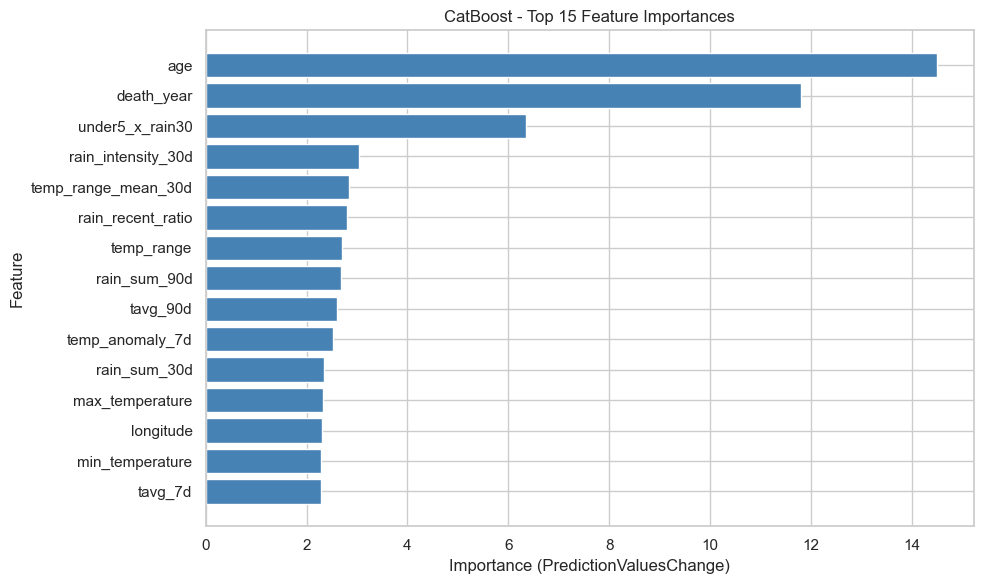

,feature,importance
0,age,14.509048
23,death_year,11.813760
37,under5_x_rain30,6.358094
27,rain_intensity_30d,3.037995
20,temp_range_mean_30d,2.835912
28,rain_recent_ratio,2.797689
30,temp_range,2.710492
15,rain_sum_90d,2.682601
19,tavg_90d,2.612188
31,temp_anomaly_7d,2.524241


In [26]:
# CatBoost - Feature Importance
# Default CatBoostClassifier importance type is PredictionValuesChange -
# how much the prediction changes on average if the feature value changes
catboost_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': catboost_model.feature_importances_,
}).sort_values('importance', ascending=False)

top_n = 15
top_catboost_importance = catboost_importance.head(top_n).sort_values('importance')

plt.figure(figsize=(10, 6))
plt.barh(top_catboost_importance['feature'], top_catboost_importance['importance'], color='steelblue')
plt.title(f'CatBoost - Top {top_n} Feature Importances')
plt.xlabel('Importance (PredictionValuesChange)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

catboost_importance.head(top_n)

Dropping 8 low-importance (noise) features:
['is_rainy_season', 'region_Iganga', 'region_Entebbe City', 'region_Bugweri', 'region_Mayuge', 'zone_Rural', 'region_Western Region', 'hot_days_30d']

F1-score:        0.7714  (vs 0.7638 with all features)
ROC-AUC:          0.8041  (vs 0.8117 with all features)
Combined (60/40): 0.7845  (vs 0.7829 with all features)

              precision    recall  f1-score   support

           0       0.58      0.71      0.64       220
           1       0.82      0.73      0.77       409

    accuracy                           0.72       629
   macro avg       0.70      0.72      0.71       629
weighted avg       0.74      0.72      0.73       629



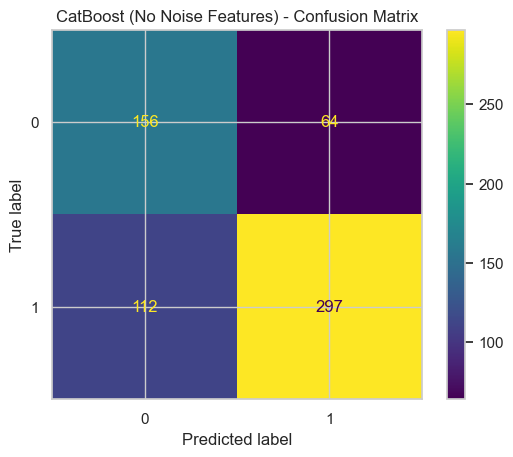

In [27]:
# CatBoost without noise features
# Same relative cutoff as the RF/XGBoost denoising steps (0.5% of total
# importance) - CatBoost's importance scale sums to ~100 rather than 1,
# so the threshold is expressed relative to the total instead of a fixed number
noise_threshold_frac = 0.005
catboost_noise_features = catboost_importance.loc[
    catboost_importance['importance'] < noise_threshold_frac * catboost_importance['importance'].sum(),
    'feature'
].tolist()

print(f"Dropping {len(catboost_noise_features)} low-importance (noise) features:")
print(catboost_noise_features)

X_train_denoised_catboost = X_train.drop(columns=catboost_noise_features)
X_val_denoised_catboost = X_val.drop(columns=catboost_noise_features)

catboost_denoised_model = CatBoostClassifier(
    n_estimators=300,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0,
)
catboost_denoised_model.fit(X_train_denoised_catboost, y_train)

y_val_pred_catboost_denoised = catboost_denoised_model.predict(X_val_denoised_catboost)
y_val_proba_catboost_denoised = catboost_denoised_model.predict_proba(X_val_denoised_catboost)[:, 1]

f1_catboost_denoised = f1_score(y_val, y_val_pred_catboost_denoised)
auc_catboost_denoised = roc_auc_score(y_val, y_val_proba_catboost_denoised)
combined_score_catboost_denoised = 0.6 * f1_catboost_denoised + 0.4 * auc_catboost_denoised

print()
print(f"F1-score:        {f1_catboost_denoised:.4f}  (vs {f1_catboost:.4f} with all features)")
print(f"ROC-AUC:          {auc_catboost_denoised:.4f}  (vs {auc_catboost:.4f} with all features)")
print(f"Combined (60/40): {combined_score_catboost_denoised:.4f}  (vs {combined_score_catboost:.4f} with all features)")
print()
print(classification_report(y_val, y_val_pred_catboost_denoised))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_catboost_denoised)
plt.title('CatBoost (No Noise Features) - Confusion Matrix')
plt.show()

In [28]:
# 5-fold stratified cross-validation on the FULL labelled data (X, y)
# Compares all models + Extra Trees + a soft-voting ensemble, so differences
# aren't driven by one lucky 629-row validation split.
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def fit_predict_lr(X_tr, y_tr, X_te):
    # scaler is fit inside each fold to avoid leakage
    pre = ColumnTransformer([('scale', StandardScaler(), numeric_features)], remainder='passthrough')
    pipe = Pipeline([
        ('pre', pre),
        ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
    ])
    return pipe.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

def fit_predict_rf(X_tr, y_tr, X_te):
    m = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
    return m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

def fit_predict_rf_denoised(X_tr, y_tr, X_te):
    return fit_predict_rf(X_tr.drop(columns=noise_features), y_tr, X_te.drop(columns=noise_features))

def fit_predict_et(X_tr, y_tr, X_te):
    m = ExtraTreesClassifier(n_estimators=500, class_weight='balanced', random_state=42)
    return m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

def fit_predict_xgb(X_tr, y_tr, X_te):
    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    m = XGBClassifier(n_estimators=300, scale_pos_weight=spw, random_state=42, eval_metric='logloss')
    return m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

def fit_predict_catboost(X_tr, y_tr, X_te):
    m = CatBoostClassifier(n_estimators=300, auto_class_weights='Balanced', random_state=42, verbose=0)
    return m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

cv_models = {
    'Logistic Regression': fit_predict_lr,
    'Random Forest': fit_predict_rf,
    'Random Forest (no noise)': fit_predict_rf_denoised,
    'Extra Trees': fit_predict_et,
    'XGBoost': fit_predict_xgb,
    'CatBoost': fit_predict_catboost,
}

oof = {name: np.zeros(len(y)) for name in cv_models}
fold_id = np.zeros(len(y), dtype=int)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y)):
    X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
    y_tr = y.iloc[tr_idx]
    fold_id[te_idx] = fold
    for name, fn in cv_models.items():
        oof[name][te_idx] = fn(X_tr, y_tr, X_te)

# Soft-voting ensemble = mean of LR, RF and CatBoost probabilities (no refit needed)
oof['Ensemble (LR+RF+CatBoost)'] = np.mean(
    [oof['Logistic Regression'], oof['Random Forest'], oof['CatBoost']], axis=0
)

y_arr = y.to_numpy()
thresholds = np.arange(0.30, 0.71, 0.01)
rows = []
for name, proba in oof.items():
    f1s, aucs = [], []
    for fold in range(skf.get_n_splits()):
        m = fold_id == fold
        f1s.append(f1_score(y_arr[m], (proba[m] >= 0.5).astype(int)))
        aucs.append(roc_auc_score(y_arr[m], proba[m]))
    f1_by_t = [f1_score(y_arr, (proba >= t).astype(int)) for t in thresholds]
    best_t = thresholds[int(np.argmax(f1_by_t))]
    rows.append({
        'model': name,
        'F1@0.5': np.mean(f1s),
        'AUC': np.mean(aucs),
        'combined': 0.6 * np.mean(f1s) + 0.4 * np.mean(aucs),
        'combined_std': np.std([0.6 * f + 0.4 * a for f, a in zip(f1s, aucs)]),
        'best_thresh': best_t,
        'F1@best_thresh': max(f1_by_t),
    })

cv_results = pd.DataFrame(rows).set_index('model').sort_values('combined', ascending=False)
cv_results.round(4)

,F1@0.5,AUC,combined,combined_std,best_thresh,F1@best_thresh
model,,,,,,
Random Forest (no noise),0.7959,0.8042,0.7992,0.0148,0.38,0.8082
Random Forest,0.7956,0.8015,0.7979,0.0166,0.37,0.8083
Extra Trees,0.7964,0.7951,0.7959,0.0117,0.38,0.8073
Ensemble (LR+RF+CatBoost),0.7823,0.8113,0.7939,0.0180,0.34,0.8165
XGBoost,0.7829,0.7885,0.7851,0.0163,0.30,0.7923
Logistic Regression,0.7649,0.8063,0.7815,0.0104,0.30,0.8122
CatBoost,0.7655,0.8049,0.7812,0.0216,0.31,0.8062


In [29]:
# Denoise EVERY model inside cross-validation, then compare all variants.
# Noise features are selected per fold from that fold's training data only
# (fit -> importance -> drop features under 0.5% of total importance -> refit),
# so the selection never sees the held-out fold. Reuses skf / fold_id / oof
# from the previous CV cell.
noise_frac = 0.005

def build_lr(X_tr, y_tr):
    num = [c for c in numeric_features if c in X_tr.columns]
    pre = ColumnTransformer([('scale', StandardScaler(), num)], remainder='passthrough')
    pipe = Pipeline([
        ('pre', pre),
        ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
    ])
    return pipe.fit(X_tr, y_tr)

def imp_lr(m, X_tr):
    names = [n.split('__', 1)[1] for n in m.named_steps['pre'].get_feature_names_out()]
    return pd.Series(np.abs(m.named_steps['lr'].coef_[0]), index=names)

def build_rf(X_tr, y_tr):
    return RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42).fit(X_tr, y_tr)

def build_et(X_tr, y_tr):
    return ExtraTreesClassifier(n_estimators=500, class_weight='balanced', random_state=42).fit(X_tr, y_tr)

def build_xgb(X_tr, y_tr):
    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    return XGBClassifier(n_estimators=300, scale_pos_weight=spw, random_state=42, eval_metric='logloss').fit(X_tr, y_tr)

def build_cb(X_tr, y_tr):
    return CatBoostClassifier(n_estimators=300, auto_class_weights='Balanced', random_state=42, verbose=0).fit(X_tr, y_tr)

def imp_tree(m, X_tr):
    return pd.Series(m.feature_importances_, index=X_tr.columns)

denoise_specs = {
    'Logistic Regression': (build_lr, imp_lr),
    'Random Forest': (build_rf, imp_tree),
    'Extra Trees': (build_et, imp_tree),
    'XGBoost': (build_xgb, imp_tree),
    'CatBoost': (build_cb, imp_tree),
}

oof_dn = {f'{name} [denoised]': np.zeros(len(y)) for name in denoise_specs}
dropped_per_fold = {name: [] for name in denoise_specs}

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y)):
    X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
    y_tr = y.iloc[tr_idx]
    for name, (build, imp_fn) in denoise_specs.items():
        first = build(X_tr, y_tr)
        imp = imp_fn(first, X_tr)
        imp = imp / imp.sum()
        drop = imp[imp < noise_frac].index.tolist()
        dropped_per_fold[name].append(set(drop))
        final = build(X_tr.drop(columns=drop), y_tr)
        oof_dn[f'{name} [denoised]'][te_idx] = final.predict_proba(X_te.drop(columns=drop))[:, 1]

oof_dn['Ensemble (LR+RF+CatBoost) [denoised]'] = np.mean(
    [oof_dn['Logistic Regression [denoised]'],
     oof_dn['Random Forest [denoised]'],
     oof_dn['CatBoost [denoised]']], axis=0
)

print("Features dropped in ALL 5 folds (stable noise):")
for name, sets in dropped_per_fold.items():
    print(f"  {name}: {sorted(set.intersection(*sets))}")

def evaluate_oof(oof_dict):
    rows = []
    for name, proba in oof_dict.items():
        f1s, aucs = [], []
        for fold in range(skf.get_n_splits()):
            m = fold_id == fold
            f1s.append(f1_score(y_arr[m], (proba[m] >= 0.5).astype(int)))
            aucs.append(roc_auc_score(y_arr[m], proba[m]))
        f1_by_t = [f1_score(y_arr, (proba >= t).astype(int)) for t in thresholds]
        rows.append({
            'model': name,
            'F1@0.5': np.mean(f1s),
            'AUC': np.mean(aucs),
            'combined': 0.6 * np.mean(f1s) + 0.4 * np.mean(aucs),
            'combined_std': np.std([0.6 * f + 0.4 * a for f, a in zip(f1s, aucs)]),
            'best_thresh': thresholds[int(np.argmax(f1_by_t))],
            'F1@best_thresh': max(f1_by_t),
        })
    return pd.DataFrame(rows).set_index('model')

full_feature_oof = {k: v for k, v in oof.items() if k != 'Random Forest (no noise)'}
cv_results_all = evaluate_oof({**full_feature_oof, **oof_dn}).sort_values('combined', ascending=False)
cv_results_all.round(4)

Features dropped in ALL 5 folds (stable noise):
  Logistic Regression: ['hot_days_30d', 'ndvi_30d', 'ndvi_90d']
  Random Forest: ['hot_days_30d', 'is_rainy_season', 'region_Bugweri', 'region_Entebbe City', 'region_Iganga', 'region_Mayuge', 'region_Western Region', 'zone_Rural']
  Extra Trees: ['hot_days_30d', 'region_Entebbe City', 'region_Western Region']
  XGBoost: ['hot_days_30d', 'is_elderly', 'is_infant', 'is_under5', 'log_precipitation', 'region_Entebbe City', 'region_Western Region']
  CatBoost: ['hot_days_30d', 'is_rainy_season', 'region_Bugweri', 'region_Entebbe City', 'region_Iganga', 'region_Mayuge', 'region_Western Region', 'zone_Rural']


,F1@0.5,AUC,combined,combined_std,best_thresh,F1@best_thresh
model,,,,,,
Random Forest [denoised],0.7959,0.8042,0.7992,0.0148,0.38,0.8082
Random Forest,0.7956,0.8015,0.7979,0.0166,0.37,0.8083
Extra Trees,0.7964,0.7951,0.7959,0.0117,0.38,0.8073
Extra Trees [denoised],0.7966,0.7945,0.7958,0.0160,0.33,0.8063
Ensemble (LR+RF+CatBoost),0.7823,0.8113,0.7939,0.0180,0.34,0.8165
Ensemble (LR+RF+CatBoost) [denoised],0.7783,0.8123,0.7919,0.0193,0.32,0.8152
XGBoost,0.7829,0.7885,0.7851,0.0163,0.30,0.7923
XGBoost [denoised],0.7823,0.7880,0.7846,0.0155,0.30,0.7921
Logistic Regression [denoised],0.7671,0.8071,0.7831,0.0110,0.30,0.8104


In [37]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Custom scorer matching your 60/40 F1/AUC combined metric
def combined_scorer(estimator, X, y):
    proba = estimator.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return 0.6 * f1_score(y, pred) + 0.4 * roc_auc_score(y, proba)

param_distributions = {
    'n_estimators': [200, 300, 400, 500, 600, 800],
    'max_depth': [None, 5, 8, 10, 15, 20, 30],
    'min_samples_split': [2, 4, 6, 8, 10, 15, 20],
    'min_samples_leaf': [1, 2, 3, 4, 6, 8],
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.7, None],
    'bootstrap': [True, False],
    'class_weight': ['balanced', 'balanced_subsample'],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=100,               # raise for a more thorough search, lower if it's too slow
    scoring=combined_scorer,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
print("Best CV combined score:", rf_search.best_score_)

rf_best_model = rf_search.best_estimator_

y_val_pred_rf_best = rf_best_model.predict(X_val)
y_val_proba_rf_best = rf_best_model.predict_proba(X_val)[:, 1]

f1_rf_best = f1_score(y_val, y_val_pred_rf_best)
auc_rf_best = roc_auc_score(y_val, y_val_proba_rf_best)
combined_score_rf_best = 0.6 * f1_rf_best + 0.4 * auc_rf_best

print(f"F1-score:        {f1_rf_best:.4f}  (vs {f1_rf:.4f} baseline)")
print(f"ROC-AUC:          {auc_rf_best:.4f}  (vs {auc_rf:.4f} baseline)")
print(f"Combined (60/40): {combined_score_rf_best:.4f}  (vs {combined_score_rf:.4f} baseline)")
print()
print(classification_report(y_val, y_val_pred_rf_best))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_rf_best)
plt.title('Random Forest (Tuned) - Confusion Matrix')
plt.show()

Fitting 5 folds for each of 100 candidates, totalling 500 fits


KeyboardInterrupt: 

In [36]:
# Random Forest -> predictions on the test data -> submission file
# Apply the SAME preprocessing that was applied to train_merged.
test_df = test_merged.copy()
test_ids = test_df['ID']

# Location cleanup + region
test_df['location'] = (
    test_df['location']
    .str.replace('Propeer', 'Proper', regex=False)
    .str.replace('Buwoya', 'Buwaya', regex=False)
    .str.replace(', Eastern Region', '', regex=False)
    .str.replace(r',\s*,', ',', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.replace(r'\s*,\s*', ', ', regex=True)
    .str.title()
)
test_df['region'] = test_df['location'].str.split(',').str[-2].str.strip()

# Dates and engineered features
test_df['deathdate'] = pd.to_datetime(test_df['deathdate'])
test_df['death_year'] = test_df['deathdate'].dt.year
test_df['death_month'] = test_df['deathdate'].dt.month
test_df['is_rainy_season'] = test_df['death_month'].isin([3, 4, 5, 9, 10, 11]).astype(int)

test_df['log_precipitation'] = np.log1p(test_df['precipitation'])
test_df['rain_intensity_30d'] = test_df['rain_sum_30d'] / (test_df['rain_days_30d'] + 1)
test_df['rain_recent_ratio'] = test_df['rain_sum_7d'] / (test_df['rain_sum_30d'] + 1)
test_df['rain_30d_vs_90d'] = test_df['rain_sum_30d'] / (test_df['rain_sum_90d'] + 1)
test_df['temp_range'] = test_df['max_temperature'] - test_df['min_temperature']
test_df['temp_anomaly_7d'] = test_df['tavg_7d'] - test_df['tavg_90d']
test_df['heat_stress_30d'] = test_df['tmax_30d'] - test_df['tavg_90d']
test_df['ndvi_change'] = test_df['ndvi_30d'] - test_df['ndvi_90d']
test_df['is_infant'] = (test_df['age'] == 0).astype(int)
test_df['is_under5'] = (test_df['age'] < 5).astype(int)
test_df['is_elderly'] = (test_df['age'] >= 60).astype(int)
test_df['under5_x_rain30'] = test_df['is_under5'] * test_df['rain_sum_30d']

# One-hot encode with the encoder ALREADY fitted on train (transform, not fit)
encoded_test = pd.DataFrame(
    encoder.transform(test_df[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=test_df.index,
)
test_df = pd.concat([test_df.drop(columns=categorical_cols), encoded_test], axis=1)

# Same columns, same order as the training features
X_test = test_df.reindex(columns=X.columns)
assert X_test.notna().all().all(), "X_test has missing values / unmatched columns"

# Refit Random Forest on ALL labelled data, then predict the test set
final_rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
final_rf.fit(X, y)

test_proba = final_rf.predict_proba(X_test)[:, 1]   # TargetRAUC
test_pred = (test_proba >= 0.5).astype(int)         # TargetF1 (default 0.5 threshold)

submission = pd.DataFrame({
    'ID': test_ids,
    'TargetF1': test_pred,
    'TargetRAUC': test_proba,
})
submission.to_csv('submission.csv', index=False)

print(submission.shape, "| predicted climate-sensitive:", test_pred.mean().round(3))
submission.head()


c:\python311\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


(1030, 3) | predicted climate-sensitive: 0.744


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.476667
1,ID_6EDEA907,1,0.703333
2,ID_B9FFC8D8,1,0.523333
3,ID_74C6C94E,1,0.583333
4,ID_0E02825D,1,0.723333
